# 6. Análisis multivariado (2.4)

Reducción de dimensionalidad exploratoria (PCA y t-SNE solo como herramienta visual),
atípicos multivariados (distancia de Mahalanobis robusta e Isolation Forest) y
estructura de grupos (k-means). Se usan las numéricas **no redundantes** identificadas en
el capítulo 5, estandarizadas con estadísticos del entrenamiento. Solo entrenamiento.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
train = load_train()
y = train[TARGET]
NUM_M = ["sales", "order_item_quantity", "order_item_discount_rate", "order_item_profit_ratio", "items_in_order",
         "orders_prev_7d", "order_hour_sin", "order_hour_cos", "order_dow_sin", "order_dow_cos",
         "order_month_sin", "order_month_cos", LAT, LON, "days_shipping_scheduled"]
Z = StandardScaler().fit_transform(train[NUM_M])
rng = np.random.default_rng(RANDOM_STATE)

## PCA: varianza explicada y estructura

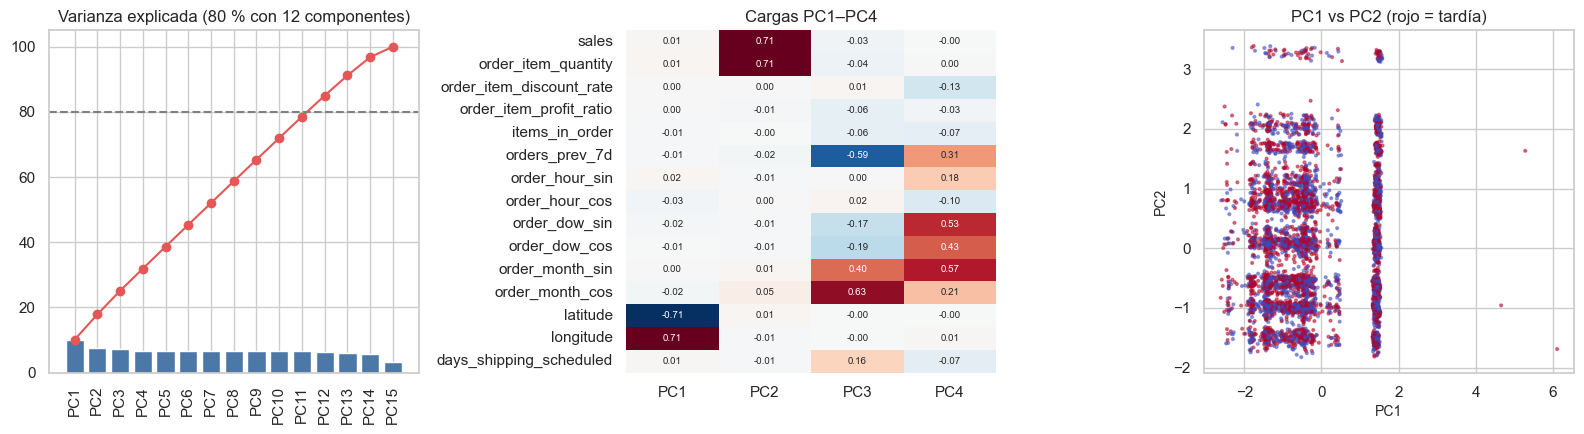

,componente,varianza_%,acumulada_%
0,PC1,10.15,10.15
1,PC2,7.72,17.86
2,PC3,7.27,25.13
3,PC4,6.79,31.91
4,PC5,6.75,38.67
5,PC6,6.71,45.37
6,PC7,6.68,52.06
7,PC8,6.68,58.73


In [2]:
pca = PCA(random_state=RANDOM_STATE).fit(Z)
var = pd.DataFrame({"componente": [f"PC{i + 1}" for i in range(len(NUM_M))], "varianza_%": 100 * pca.explained_variance_ratio_})
var["acumulada_%"] = var["varianza_%"].cumsum()
var.to_csv(TABLES / "pca_varianza.csv", index=False)
k80 = int((var["acumulada_%"] < 80).sum() + 1)
cargas = pd.DataFrame(pca.components_[:4].T, index=NUM_M, columns=["PC1", "PC2", "PC3", "PC4"])
cargas.to_csv(TABLES / "pca_cargas.csv")

idx = rng.choice(len(train), 6000, replace=False)
P = pca.transform(Z[idx])[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(var["componente"], var["varianza_%"], color="#4c78a8"); axes[0].plot(var["componente"], var["acumulada_%"], "o-", color="#e45756")
axes[0].axhline(80, ls="--", color="gray"); axes[0].set_title(f"Varianza explicada (80 % con {k80} componentes)"); axes[0].tick_params(axis="x", rotation=90)
sns.heatmap(cargas, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[1], cbar=False, annot_kws={"size": 7}); axes[1].set_title("Cargas PC1–PC4")
sc = axes[2].scatter(P[:, 0], P[:, 1], c=y.iloc[idx], cmap="coolwarm", s=4, alpha=0.5)
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].set_title("PC1 vs PC2 (rojo = tardía)")
plt.tight_layout(); save_figure(fig, "06_pca.png"); plt.show()
display(var.round(2).head(8))

**Interpretación.** La varianza está **repartida**: se necesitan muchas componentes
para llegar al 80 %, porque las variables son casi independientes (cap. 5). PC1 es el
eje «monto del pedido» (ventas y cantidad), PC2 el eje geográfico (latitud/longitud).
Ninguna componente separa entregas tardías de no tardías: los puntos rojos y azules se
superponen. La **dimensionalidad efectiva es alta y la señal está en una variable
(el modo de envío)**, no en una combinación de muchas.

c:\Users\juand\miniconda3\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\juand\miniconda3\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\juand\miniconda3\envs\ml_venv\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\juand\miniconda3\envs\ml_venv\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\juand\miniconda3\envs\ml_venv\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _win

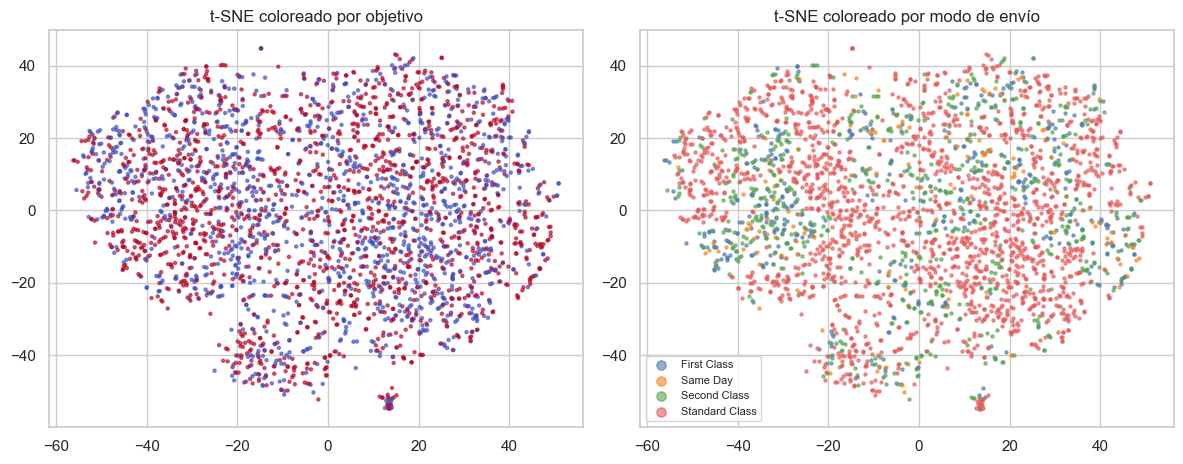

In [3]:
idx_t = rng.choice(len(train), 3000, replace=False)
emb = TSNE(n_components=2, perplexity=40, random_state=RANDOM_STATE, init="pca").fit_transform(Z[idx_t])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(emb[:, 0], emb[:, 1], c=y.iloc[idx_t], cmap="coolwarm", s=5, alpha=0.6); axes[0].set_title("t-SNE coloreado por objetivo")
modo = train["shipping_mode"].iloc[idx_t]
for m, c in zip(sorted(modo.unique()), ["#4c78a8", "#f58518", "#54a24b", "#e45756"]):
    mask = (modo == m).to_numpy()
    axes[1].scatter(emb[mask, 0], emb[mask, 1], s=5, alpha=0.6, color=c, label=m)
axes[1].legend(markerscale=3, fontsize=8); axes[1].set_title("t-SNE coloreado por modo de envío")
plt.tight_layout(); save_figure(fig, "06_tsne.png"); plt.show()

**Interpretación (solo visual, no inferencial).** t-SNE forma grupos definidos sobre
todo por el modo de envío (días programados) y por la ubicación; dentro de cada grupo
los colores del objetivo vuelven a mezclarse. Confirma que la estructura multivariada
**no** contiene una separación oculta de las clases.

## Atípicos multivariados: Mahalanobis robusta e Isolation Forest

Mahalanobis **robusta (MCD)** marcaría 39,2 % de las filas como atípicas: con datos multimodales el núcleo de MCD es uno solo de los modos (Puerto Rico o el continente) y todo lo demás parece atípico. Se usa la distancia **clásica**.

,grupo,líneas,tardía_%,líneas_%
0,"Mahalanobis clásica > χ²(0,999)",2432,54.36,1.70
1,Isolation Forest,1431,53.32,1.00
2,ambos,846,53.55,0.59
3,resto,140058,54.92,97.89


,mediana atípicos IF,mediana resto
sales,250.000,179.970
order_item_quantity,4.000,1.000
order_item_discount_rate,0.130,0.090
order_item_profit_ratio,-1.550,0.270
items_in_order,3.000,4.000
orders_prev_7d,398.000,399.000
latitude,33.833,33.139
longitude,-98.191,-76.761


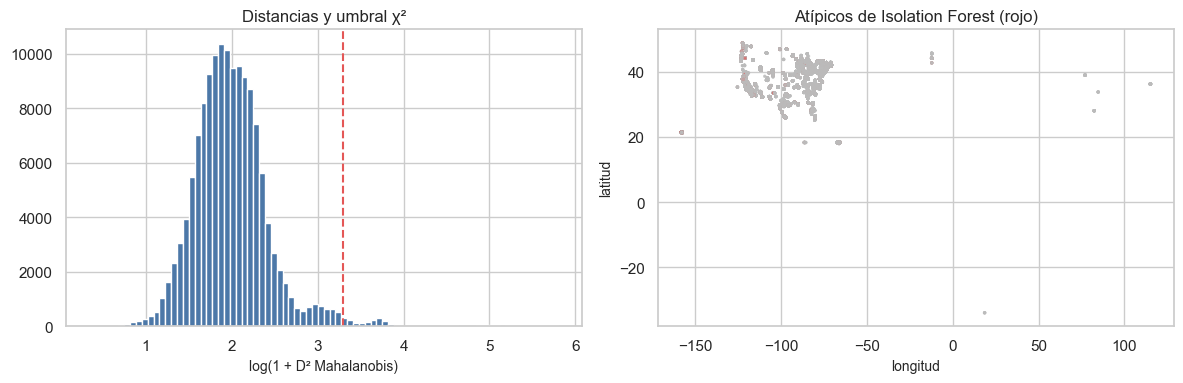

In [4]:
cont = ["sales", "order_item_quantity", "order_item_discount_rate", "order_item_profit_ratio", "items_in_order", "orders_prev_7d", LAT, LON]
Zc = StandardScaler().fit_transform(train[cont])
idx_m = rng.choice(len(train), 20000, replace=False)
mcd = MinCovDet(random_state=RANDOM_STATE).fit(Zc[idx_m])
umbral = stats.chi2.ppf(0.999, df=len(cont))
pct_robusta = float((mcd.mahalanobis(Zc) > umbral).mean())
# La versión robusta (MCD) marca demasiadas filas porque los datos son multimodales (Puerto Rico vs. continente)
# y discretos: el «núcleo» que elige MCD es un solo modo. Se usa la covarianza clásica para la decisión.
inv = np.linalg.pinv(np.cov(Zc, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Zc, inv, Zc)
out_mah = d2 > umbral
md_out(f"Mahalanobis **robusta (MCD)** marcaría {es(pct_robusta, 1, pct=True)} de las filas como atípicas: con datos multimodales el "
       "núcleo de MCD es uno solo de los modos (Puerto Rico o el continente) y todo lo demás parece atípico. Se usa la distancia **clásica**.")

# Para ahorrar memoria, el bosque se ajusta con una muestra de 20.000 filas (cada árbol usa 256 de todos modos)
# y se aplica a todas las filas por bloques.
import gc
gc.collect()
iso = IsolationForest(n_estimators=100, max_samples=256, contamination=0.01, random_state=RANDOM_STATE).fit(Zc[idx_m])
umbral_iso = np.quantile(np.concatenate([iso.score_samples(Zc[i:i + 20000]) for i in range(0, len(Zc), 20000)]), 0.01)
out_iso = np.concatenate([iso.score_samples(Zc[i:i + 20000]) for i in range(0, len(Zc), 20000)]) <= umbral_iso

perfil = pd.DataFrame({
    "grupo": ["Mahalanobis clásica > χ²(0,999)", "Isolation Forest", "ambos", "resto"],
    "líneas": [out_mah.sum(), out_iso.sum(), (out_mah & out_iso).sum(), (~out_mah & ~out_iso).sum()],
    "tardía_%": [100 * y[out_mah].mean(), 100 * y[out_iso].mean(), 100 * y[out_mah & out_iso].mean(), 100 * y[~out_mah & ~out_iso].mean()],
})
perfil["líneas_%"] = 100 * perfil["líneas"] / len(train)
perfil.to_csv(TABLES / "atipicos_multivariados.csv", index=False)
display(perfil.round(2))
comp = pd.concat([train.loc[out_iso, cont].median().rename("mediana atípicos IF"), train.loc[~out_iso, cont].median().rename("mediana resto")], axis=1)
display(comp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(d2), bins=80, color="#4c78a8"); axes[0].axvline(np.log1p(umbral), color="#e45756", ls="--")
axes[0].set_xlabel("log(1 + D² Mahalanobis)"); axes[0].set_title("Distancias y umbral χ²")
axes[1].scatter(train[LON], train[LAT], s=2, c=np.where(out_iso, "#e45756", "#bbbbbb"), alpha=0.5)
axes[1].set_xlabel("longitud"); axes[1].set_ylabel("latitud"); axes[1].set_title("Atípicos de Isolation Forest (rojo)")
plt.tight_layout(); save_figure(fig, "06_atipicos.png"); plt.show()

**Interpretación.** Isolation Forest (ajustado con una muestra de 20.000 líneas y aplicado a todas)
marca el 1 % más aislado. Los
atípicos multivariados son combinaciones poco frecuentes (ventas con pérdida grande,
ubicaciones fuera del territorio continental y de Puerto Rico, primera semana sin
historia de carga). Su tasa de entregas tardías es **similar** a la del resto,
de modo que no son una subpoblación con otro comportamiento del objetivo. **Decisión:**
se conservan; no se eliminan filas por ser atípicas (serían pedidos reales en
producción). La regresión logística es sensible a valores extremos en las numéricas, lo
que se mitiga con la transformación log y el escalado (cap. 10).

## Estructura de grupos (k-means exploratorio)

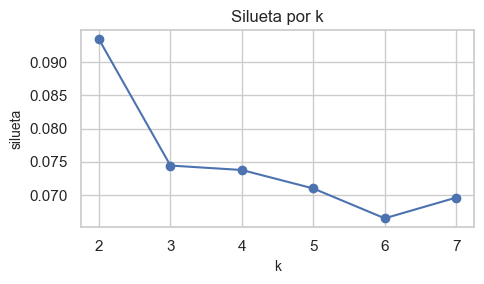

Mejor k por silueta: **2** (silueta = 0,093). Perfil de los grupos:

,líneas,tardía_pct,dias_prog,ventas,lat,lon
cluster,,,,,,
0,85854,54.88,2.93,179.97,37.67,-92.22
1,57221,54.94,2.94,179.97,18.25,-66.37


In [5]:
idx_k = rng.choice(len(train), 15000, replace=False)
sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(Z[idx_k])
    sil[k] = silhouette_score(Z[idx_k], km.labels_, sample_size=5000, random_state=RANDOM_STATE)
k_best = max(sil, key=sil.get)
km = KMeans(n_clusters=k_best, n_init=10, random_state=RANDOM_STATE).fit(Z)
cl = pd.Series(km.labels_, name="cluster")
perfil_cl = train.assign(cluster=cl).groupby("cluster").agg(
    líneas=(TARGET, "size"), tardía_pct=(TARGET, lambda s: 100 * s.mean()),
    dias_prog=("days_shipping_scheduled", "mean"), ventas=("sales", "median"), lat=(LAT, "median"), lon=(LON, "median"))
perfil_cl.to_csv(TABLES / "clusters_perfil.csv")
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(list(sil), list(sil.values()), "o-"); ax.set_xlabel("k"); ax.set_ylabel("silueta"); ax.set_title("Silueta por k")
plt.tight_layout(); save_figure(fig, "06_silueta.png"); plt.show()
md_out(f"Mejor k por silueta: **{k_best}** (silueta = {es(sil[k_best], 3)}). Perfil de los grupos:")
display(perfil_cl.round(2))

**Interpretación.** La silueta es **baja** (< 0,25): no hay grupos naturales bien
separados; k-means corta el espacio por ubicación y por días programados. Con k = 2 separa Puerto Rico
del continente, y ambos grupos tienen **la misma** tasa de entregas tardías.

**Conclusión del multivariado.** (i) La dimensionalidad efectiva es alta y las numéricas
son casi independientes entre sí una vez eliminadas las redundancias; (ii) no hay
subpoblaciones que requieran modelos separados; (iii) la señal del objetivo está en el
modo de envío y es débil en todo lo demás. Un modelo lineal con el modo de envío y
controles es una línea base adecuada.